# NHTS 2022 Correlation and Association Analysis

This notebook extends the initial data exploration for the research question:

> Among adults making weekday home-based work trips in the United States, how are traveller, household, trip, and accessibility characteristics associated with choosing car, public transport, walking, or cycling?

It does not fit a regression or machine-learning model. It examines distributions, correlations among predictors, and associations with transport mode.

Three different measures are used because the variables do not all have the same meaning:

- **Spearman correlation** for numerical or ordered predictors. It measures whether two variables tend to move in the same or opposite direction.
- **Cramer's V** for two categorical variables. It measures association without pretending category codes are numerical quantities.
- **Correlation ratio (eta)** for a numerical predictor and a categorical mode outcome. It measures how strongly the numerical variable differs among modes, but it has no positive or negative direction.

All correlations and significance tests here are exploratory and unweighted. Survey-weighted mode shares are shown separately. The p-values do not yet account for repeated trips by the same person, household clustering, survey strata, or multiple testing.

## 1. Environment and configuration

Use the Anaconda base environment and select:

```text
Kernel -> Change Kernel -> Python 3 (ipykernel)
```

The only setting normally changed is `DATA_DIR`.

In [1]:
import sys
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal, spearmanr

DATA_DIR = Path("./Data")
SPECIAL_CODES = {-1, -7, -8, -9}

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print(f"Python executable: {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Data directory exists: {DATA_DIR.exists()}")

Python executable: C:\ProgramData\anaconda3\python.exe
Python version: 3.12.7
pandas version: 2.2.2
Data directory: D:\StatProject\Data
Data directory exists: True


## 2. Load the source tables and validate the person join

The trip table is the analytical base. `GCDWORK` comes from the person table and is joined with the composite person key `HOUSEID + PERSONID`.

The join must keep the trip-row count unchanged. Duplicate person keys are treated as an error instead of being silently removed.

In [2]:
def find_file(directory, name):
    """Find a filename recursively and case-insensitively."""
    if not directory.exists():
        return None
    wanted = name.lower()
    for path in directory.rglob("*"):
        if path.is_file() and path.name.lower() == wanted:
            return path
    return None


trip_path = find_file(DATA_DIR, "tripv2pub.csv")
person_path = find_file(DATA_DIR, "perv2pub.csv")

if trip_path is None or person_path is None:
    missing = []
    if trip_path is None:
        missing.append("tripv2pub.csv")
    if person_path is None:
        missing.append("perv2pub.csv")
    raise FileNotFoundError(
        f"Missing required file(s): {missing}. Change DATA_DIR so it points to the extracted NHTS folder."
    )

trip = pd.read_csv(trip_path, low_memory=False)
person = pd.read_csv(person_path, low_memory=False)

person_key = ["HOUSEID", "PERSONID"]
if person.duplicated(person_key).any():
    n_dup = int(person.duplicated(person_key, keep=False).sum())
    raise ValueError(f"Person table has {n_dup:,} rows with duplicate HOUSEID + PERSONID keys.")

rows_before = len(trip)
person_columns = person_key + [
    column
    for column in ["GCDWORK", "HBPPOPDN", "HTPPOPDN"]
    if column in person.columns and column not in trip.columns
]
analysis = trip.merge(
    person[person_columns],
    on=person_key,
    how="left",
    validate="many_to_one",
    indicator="_person_match",
)
rows_after = len(analysis)
unmatched_people = int((analysis["_person_match"] == "left_only").sum())
analysis = analysis.drop(columns="_person_match")

if rows_after != rows_before:
    raise RuntimeError(f"Trip rows changed from {rows_before:,} to {rows_after:,} after the person join.")

print(f"Trip file: {trip_path.resolve()}")
print(f"Person file: {person_path.resolve()}")
print(f"Trip rows before join: {rows_before:,}")
print(f"Trip rows after join:  {rows_after:,}")
print(f"Trips without a matching person: {unmatched_people:,}")
print(f"Columns after join: {analysis.shape[1]:,}")

Trip file: D:\StatProject\Data\tripv2pub.csv
Person file: D:\StatProject\Data\perv2pub.csv
Trip rows before join: 31,074
Trip rows after join:  31,074
Trips without a matching person: 0
Columns after join: 105


## 3. Define transport modes and the study population

The four filters are adult age, weekday travel, home-based work purpose, and one of the selected modes. January 2023 travel dates are retained because they can belong to the 2022 survey cycle.

`PERSONID` is not globally unique. Unique people are counted with `HOUSEID + PERSONID`.

In [3]:
MODE_MAP = {
    1: "car", 2: "car", 3: "car", 4: "car",
    8: "public_transport", 10: "public_transport", 11: "public_transport",
    12: "public_transport", 13: "public_transport",
    18: "cycling", 20: "walking",
}
MODE4_ORDER = ["car", "public_transport", "walking", "cycling"]
MODE3_ORDER = ["car", "public_transport", "active_travel"]


def normalize_integer_codes(series):
    """Convert integer-like strings/floats to nullable integers without rounding invalid fractions."""
    numeric = pd.to_numeric(series, errors="coerce")
    integer_like = numeric.where(numeric.isna() | np.isclose(numeric, np.round(numeric)))
    return integer_like.round().astype("Int64")


required = ["HOUSEID", "PERSONID", "R_AGE", "TDWKND", "TRIPPURP", "TRPTRANS"]
missing_required = [column for column in required if column not in analysis.columns]
if missing_required:
    raise KeyError(f"Required study-population columns are missing: {missing_required}")

analysis["TRPTRANS_code"] = normalize_integer_codes(analysis["TRPTRANS"])
analysis["mode_4cat"] = analysis["TRPTRANS_code"].map(MODE_MAP).fillna("other_or_excluded")

study_mask = (
    (pd.to_numeric(analysis["R_AGE"], errors="coerce") >= 18)
    & (normalize_integer_codes(analysis["TDWKND"]) == 2)
    & (normalize_integer_codes(analysis["TRIPPURP"]) == 1)
    & analysis["mode_4cat"].isin(MODE4_ORDER)
)
study = analysis.loc[study_mask].copy()
study["mode_4cat"] = pd.Categorical(study["mode_4cat"], categories=MODE4_ORDER)
study["mode_3cat"] = study["mode_4cat"].map({
    "car": "car",
    "public_transport": "public_transport",
    "walking": "active_travel",
    "cycling": "active_travel",
})
study["mode_3cat"] = pd.Categorical(study["mode_3cat"], categories=MODE3_ORDER)

unique_people = study[["HOUSEID", "PERSONID"]].drop_duplicates().shape[0]
unique_households = study["HOUSEID"].nunique()
jan_2023 = (
    study["TDAYDATE"].astype(str).str.startswith("202301").sum()
    if "TDAYDATE" in study.columns else np.nan
)

sample_summary = pd.DataFrame({
    "Measure": ["Trip records", "Unique people", "Unique households", "TDAYDATE = 202301 trips"],
    "Value": [len(study), unique_people, unique_households, jan_2023],
})
display(sample_summary)

,Measure,Value
0,Trip records,4269
1,Unique people,2384
2,Unique households,1928
3,TDAYDATE = 202301 trips,223


## 4. Mode distribution

Raw counts describe the actual statistical sample. Weighted shares using `WTTRDFIN5D` estimate weekday mode shares in the population represented by the survey.

Four-category outcome


,Mode,Unweighted count,Unweighted %,Weighted %
0,car,4062,95.15,94.86
1,public_transport,77,1.80,2.09
2,walking,99,2.32,2.39
3,cycling,31,0.73,0.67


Three-category alternative


,Mode,Unweighted count,Unweighted %,Weighted %
0,car,4062,95.15,94.86
1,public_transport,77,1.80,2.09
2,active_travel,130,3.05,3.05


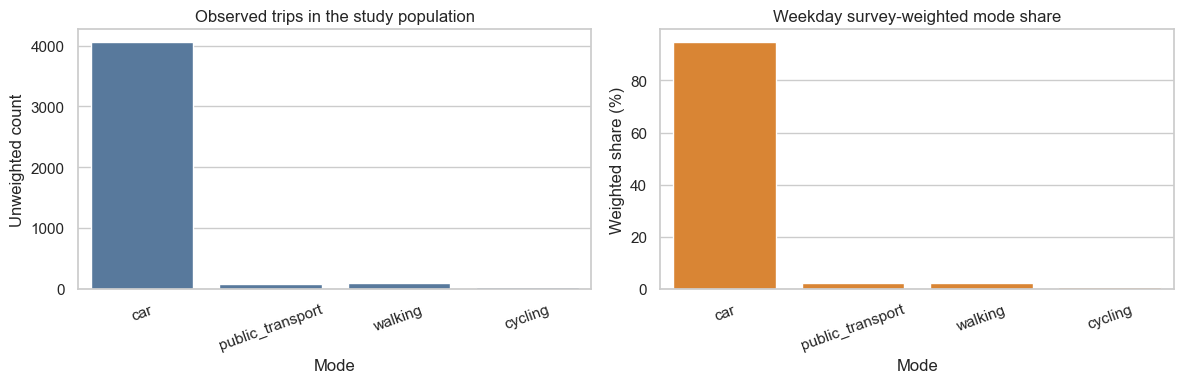

In [4]:
def mode_summary(df, mode_column, order, weight="WTTRDFIN5D"):
    counts = df[mode_column].value_counts().reindex(order, fill_value=0)
    out = pd.DataFrame({"Mode": order, "Unweighted count": counts.to_numpy()})
    out["Unweighted %"] = out["Unweighted count"] / out["Unweighted count"].sum() * 100
    if weight in df.columns:
        weighted = df.groupby(mode_column, observed=False)[weight].sum().reindex(order, fill_value=0)
        out["Weighted %"] = weighted.to_numpy() / weighted.sum() * 100
    return out


mode4_summary = mode_summary(study, "mode_4cat", MODE4_ORDER)
mode3_summary = mode_summary(study, "mode_3cat", MODE3_ORDER)

print("Four-category outcome")
display(mode4_summary.style.format({"Unweighted %": "{:.2f}", "Weighted %": "{:.2f}"}))
print("Three-category alternative")
display(mode3_summary.style.format({"Unweighted %": "{:.2f}", "Weighted %": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=mode4_summary, x="Mode", y="Unweighted count", ax=axes[0], color="#4C78A8")
axes[0].set_title("Observed trips in the study population")
axes[0].set_xlabel("Mode")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=mode4_summary, x="Mode", y="Weighted %", ax=axes[1], color="#F58518")
axes[1].set_title("Weekday survey-weighted mode share")
axes[1].set_xlabel("Mode")
axes[1].set_ylabel("Weighted share (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. Prepare analysis features

The raw source fields remain unchanged. In a separate analysis copy, special NHTS codes `-1`, `-7`, `-8`, and `-9` are converted to missing values for correlation calculations. This prevents those labels from being treated as real numerical measurements.

This is a cautious provisional rule. The official codebook must still be checked because `-1` can represent a meaningful questionnaire skip.

Derived exploratory features:

- `ZERO_VEHICLE`: household has zero vehicles.
- `VEHICLES_PER_DRIVER`: household vehicles divided by licensed drivers, where driver count is positive.
- `DEPARTURE_PERIOD`: morning peak, midday, evening peak, or night.
- `DEST_MINUS_HOME_POPDENS`: destination population density minus home population density.

In [5]:
NUMERIC_CANDIDATES = [
    "R_AGE", "HHSIZE", "HHVEHCNT", "DRVRCNT", "WRKCOUNT",
    "GCDWORK", "TRPMILES", "HBPPOPDN", "HTPPOPDN", "DBPPOPDN", "DTPPOPDN",
]
CATEGORICAL_CANDIDATES = [
    "R_SEX_IMP", "EDUC", "WORKER", "DRIVER", "HHFAMINC",
    "RAIL", "MSACAT", "URBRUR",
]

clean = study.copy()
available_source_features = [
    column for column in NUMERIC_CANDIDATES + CATEGORICAL_CANDIDATES
    if column in clean.columns
]

for column in available_source_features:
    numeric = pd.to_numeric(clean[column], errors="coerce")
    clean[column] = numeric.mask(numeric.isin(SPECIAL_CODES))

if "HHVEHCNT" in clean.columns:
    clean["ZERO_VEHICLE"] = clean["HHVEHCNT"].eq(0).map({True: "yes", False: "no"})
    clean.loc[clean["HHVEHCNT"].isna(), "ZERO_VEHICLE"] = np.nan

if {"HHVEHCNT", "DRVRCNT"}.issubset(clean.columns):
    clean["VEHICLES_PER_DRIVER"] = np.where(
        clean["DRVRCNT"] > 0,
        clean["HHVEHCNT"] / clean["DRVRCNT"],
        np.nan,
    )

if {"DBPPOPDN", "HBPPOPDN"}.issubset(clean.columns):
    clean["DEST_MINUS_HOME_POPDENS"] = clean["DBPPOPDN"] - clean["HBPPOPDN"]

if "STRTTIME" in clean.columns:
    time_value = pd.to_numeric(clean["STRTTIME"], errors="coerce")
    hour = np.floor(time_value / 100)
    minute = time_value % 100
    valid_time = hour.between(0, 23) & minute.between(0, 59)
    period = pd.Series(np.nan, index=clean.index, dtype="object")
    period.loc[valid_time & hour.between(6, 9)] = "morning_peak"
    period.loc[valid_time & hour.between(10, 15)] = "midday"
    period.loc[valid_time & hour.between(16, 18)] = "evening_peak"
    period.loc[valid_time & ((hour >= 19) | (hour <= 5))] = "night"
    clean["DEPARTURE_PERIOD"] = period

NUMERIC_FEATURES = [c for c in NUMERIC_CANDIDATES if c in clean.columns]
for derived in ["VEHICLES_PER_DRIVER", "DEST_MINUS_HOME_POPDENS"]:
    if derived in clean.columns:
        NUMERIC_FEATURES.append(derived)

CATEGORICAL_FEATURES = [c for c in CATEGORICAL_CANDIDATES if c in clean.columns]
for derived in ["ZERO_VEHICLE", "DEPARTURE_PERIOD"]:
    if derived in clean.columns:
        CATEGORICAL_FEATURES.append(derived)

print("Numerical or ordered features:")
print(NUMERIC_FEATURES)
print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

Numerical or ordered features:
['R_AGE', 'HHSIZE', 'HHVEHCNT', 'DRVRCNT', 'WRKCOUNT', 'GCDWORK', 'TRPMILES', 'HBPPOPDN', 'HTPPOPDN', 'DBPPOPDN', 'DTPPOPDN', 'VEHICLES_PER_DRIVER', 'DEST_MINUS_HOME_POPDENS']

Categorical features:
['R_SEX_IMP', 'EDUC', 'WORKER', 'DRIVER', 'HHFAMINC', 'RAIL', 'MSACAT', 'URBRUR', 'ZERO_VEHICLE', 'DEPARTURE_PERIOD']


## 6. Feature quality before correlation

A correlation can be misleading when a variable has many missing values, almost no variation, or only a few valid observations. This table shows how much usable information is available for each feature.

In [6]:
quality_rows = []
for column in NUMERIC_FEATURES + CATEGORICAL_FEATURES:
    source_special = 0
    if column in study.columns:
        source_numeric = pd.to_numeric(study[column], errors="coerce")
        source_special = int(source_numeric.isin(SPECIAL_CODES).sum())
    quality_rows.append({
        "Feature": column,
        "Analysis type": "numerical/ordered" if column in NUMERIC_FEATURES else "categorical",
        "Valid values": int(clean[column].notna().sum()),
        "Missing % after cleaning": clean[column].isna().mean() * 100,
        "Special-code records": source_special,
        "Distinct valid values": int(clean[column].nunique(dropna=True)),
        "Most common share %": (
            clean[column].value_counts(normalize=True, dropna=True).iloc[0] * 100
            if clean[column].notna().any() else np.nan
        ),
    })

quality = pd.DataFrame(quality_rows).sort_values(["Analysis type", "Feature"])
display(quality.style.format({
    "Missing % after cleaning": "{:.1f}",
    "Most common share %": "{:.1f}",
}))

,Feature,Analysis type,Valid values,Missing % after cleaning,Special-code records,Distinct valid values,Most common share %
22,DEPARTURE_PERIOD,categorical,4266,0.1,0,4,38.0
16,DRIVER,categorical,4269,0.0,0,2,97.6
14,EDUC,categorical,4269,0.0,0,8,29.2
17,HHFAMINC,categorical,4207,1.5,62,11,17.6
19,MSACAT,categorical,4269,0.0,0,4,43.5
18,RAIL,categorical,4269,0.0,0,2,79.2
13,R_SEX_IMP,categorical,4269,0.0,0,2,55.0
20,URBRUR,categorical,4269,0.0,0,2,78.3
15,WORKER,categorical,4269,0.0,0,2,96.9
21,ZERO_VEHICLE,categorical,4269,0.0,0,2,97.8


## 7. Spearman correlation among numerical and ordered predictors

Spearman's rho ranges from -1 to +1:

- Positive values mean the variables tend to increase together.
- Negative values mean one tends to decrease as the other increases.
- Values near zero indicate little monotonic relationship.

These are pairwise, unweighted sample correlations. Correlation does not establish causation.

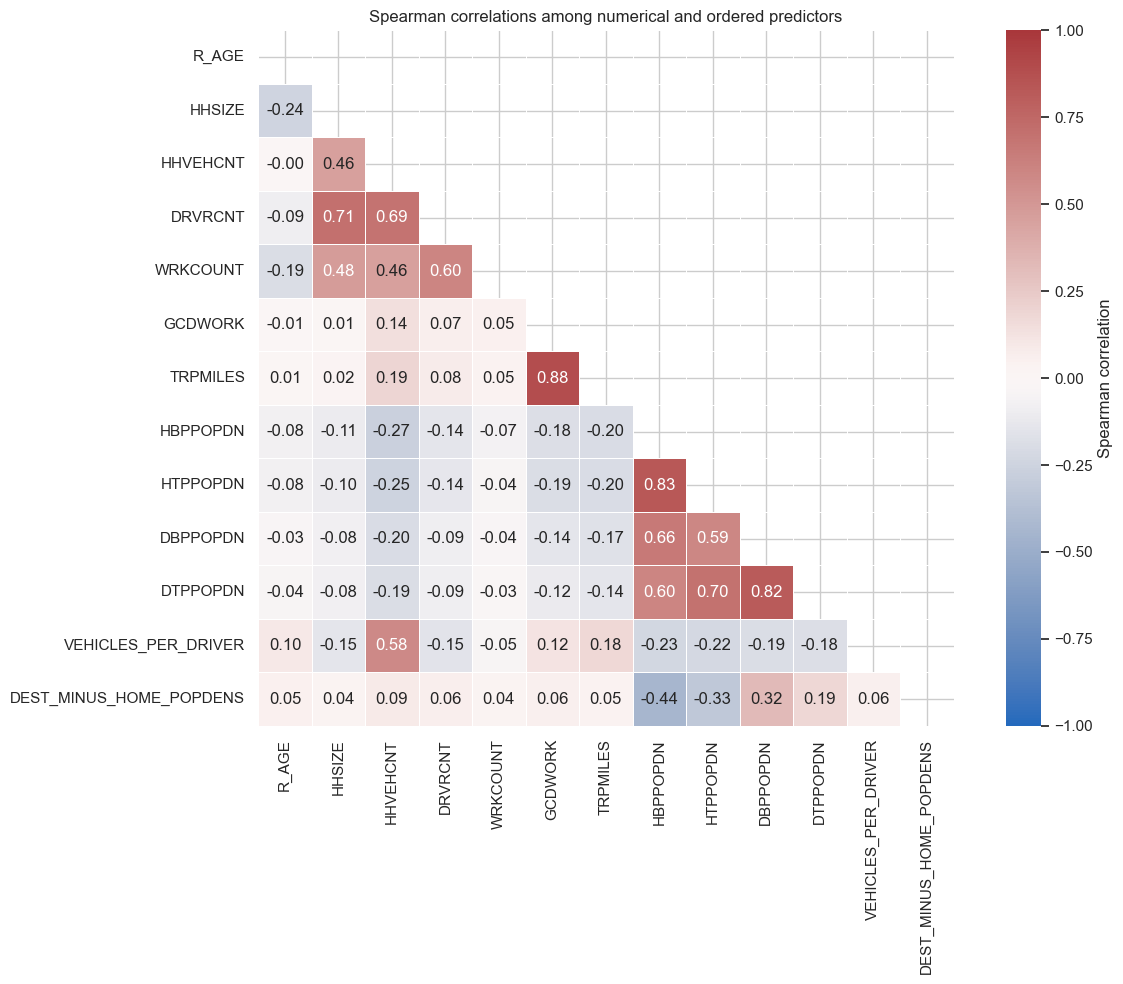

In [7]:
spearman_matrix = clean[NUMERIC_FEATURES].corr(method="spearman", min_periods=30)

mask = np.triu(np.ones_like(spearman_matrix, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(
    spearman_matrix,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
)
plt.title("Spearman correlations among numerical and ordered predictors")
plt.tight_layout()
plt.show()

In [8]:
pair_rows = []
for left, right in combinations(NUMERIC_FEATURES, 2):
    pair = clean[[left, right]].dropna()
    if len(pair) < 30 or pair[left].nunique() < 2 or pair[right].nunique() < 2:
        continue
    rho, p_value = spearmanr(pair[left], pair[right])
    pair_rows.append({
        "Feature 1": left,
        "Feature 2": right,
        "Spearman rho": rho,
        "Absolute rho": abs(rho),
        "Complete pairs": len(pair),
        "Unadjusted p-value": p_value,
    })

spearman_pairs = pd.DataFrame(pair_rows).sort_values("Absolute rho", ascending=False)
print("Strongest predictor correlations")
display(spearman_pairs.head(15).style.format({
    "Spearman rho": "{:.3f}",
    "Absolute rho": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

Strongest predictor correlations


,Feature 1,Feature 2,Spearman rho,Absolute rho,Complete pairs,Unadjusted p-value
50,GCDWORK,TRPMILES,0.884,0.884,3813,0
63,HBPPOPDN,HTPPOPDN,0.835,0.835,4237,0
72,DBPPOPDN,DTPPOPDN,0.817,0.817,4223,0
13,HHSIZE,DRVRCNT,0.707,0.707,4269,0
69,HTPPOPDN,DTPPOPDN,0.701,0.701,4231,0
23,HHVEHCNT,DRVRCNT,0.691,0.691,4269,0
64,HBPPOPDN,DBPPOPDN,0.660,0.660,4227,0
65,HBPPOPDN,DTPPOPDN,0.601,0.601,4222,0
33,DRVRCNT,WRKCOUNT,0.600,0.600,4269,0
68,HTPPOPDN,DBPPOPDN,0.590,0.590,4224,0


## 8. Cramer's V among categorical predictors

Cramer's V ranges from 0 to 1. Zero means no observed association and one means perfect association. It has no positive or negative direction.

Numeric category labels are treated as labels here. For example, the code `2` is not assumed to be twice the code `1`.

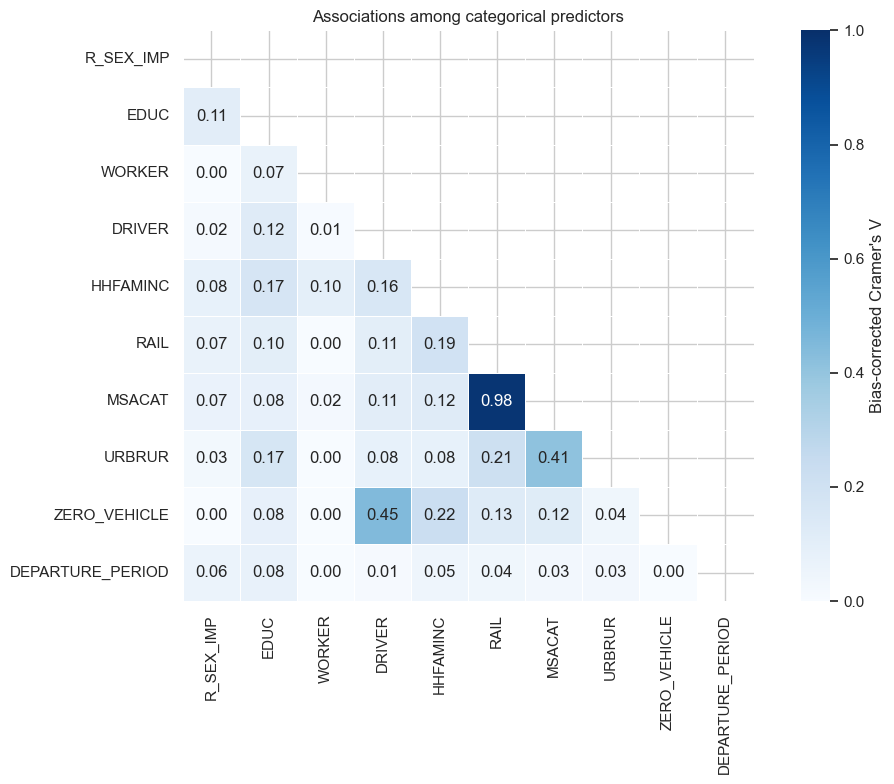

In [9]:
def cramers_v(x, y):
    """Bias-corrected Cramer's V, p-value, and complete-case count."""
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(pair["x"], pair["y"])
    n = int(table.to_numpy().sum())
    if n < 2 or min(table.shape) < 2:
        return np.nan, np.nan, n
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    phi2 = chi2 / n
    rows, cols = table.shape
    phi2_corrected = max(0, phi2 - ((cols - 1) * (rows - 1)) / (n - 1))
    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    cols_corrected = cols - ((cols - 1) ** 2) / (n - 1)
    denominator = min(cols_corrected - 1, rows_corrected - 1)
    value = np.sqrt(phi2_corrected / denominator) if denominator > 0 else np.nan
    return value, p_value, n


cramers_matrix = pd.DataFrame(
    np.eye(len(CATEGORICAL_FEATURES)),
    index=CATEGORICAL_FEATURES,
    columns=CATEGORICAL_FEATURES,
)
for left, right in combinations(CATEGORICAL_FEATURES, 2):
    value, _, _ = cramers_v(clean[left], clean[right])
    cramers_matrix.loc[left, right] = value
    cramers_matrix.loc[right, left] = value

mask = np.triu(np.ones_like(cramers_matrix, dtype=bool))
plt.figure(figsize=(11, 8))
sns.heatmap(
    cramers_matrix,
    mask=mask,
    cmap="Blues",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Bias-corrected Cramer's V"},
)
plt.title("Associations among categorical predictors")
plt.tight_layout()
plt.show()

In [10]:
categorical_pair_rows = []
for left, right in combinations(CATEGORICAL_FEATURES, 2):
    value, p_value, n = cramers_v(clean[left], clean[right])
    categorical_pair_rows.append({
        "Feature 1": left,
        "Feature 2": right,
        "Cramer's V": value,
        "Complete records": n,
        "Unadjusted p-value": p_value,
    })

categorical_pairs = pd.DataFrame(categorical_pair_rows).sort_values("Cramer's V", ascending=False)
print("Strongest categorical predictor associations")
display(categorical_pairs.head(15).style.format({
    "Cramer's V": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

Strongest categorical predictor associations


,Feature 1,Feature 2,Cramer's V,Complete records,Unadjusted p-value
35,RAIL,MSACAT,0.979,4269,0
28,DRIVER,ZERO_VEHICLE,0.446,4269,2.85e-187
39,MSACAT,URBRUR,0.414,4269,1.43e-158
33,HHFAMINC,ZERO_VEHICLE,0.223,4207,1.11e-41
36,RAIL,URBRUR,0.211,4269,1.88e-43
30,HHFAMINC,RAIL,0.194,4207,4.41e-31
11,EDUC,HHFAMINC,0.171,4207,1.03e-149
14,EDUC,URBRUR,0.167,4269,3.27e-24
24,DRIVER,HHFAMINC,0.157,4207,7.44e-20
37,RAIL,ZERO_VEHICLE,0.125,4269,1.84e-16


## 9. Numerical-feature association with transport mode

Transport mode is a nominal category, so assigning numbers such as car = 1 and transit = 2 would create a false ordering. The **correlation ratio eta** is used instead.

Eta ranges from 0 to 1. Larger values mean the numerical feature differs more across mode groups. Eta does not say which mode has the larger value, so the mode-specific summaries must be read alongside it.

The Kruskal-Wallis test provides an exploratory unadjusted p-value. It does not account for survey weights or clustering.

In [11]:
def correlation_ratio(categories, values):
    pair = pd.DataFrame({"category": categories, "value": values}).dropna()
    if len(pair) < 2 or pair["category"].nunique() < 2 or pair["value"].nunique() < 2:
        return np.nan, np.nan, len(pair)
    grand_mean = pair["value"].mean()
    total_ss = ((pair["value"] - grand_mean) ** 2).sum()
    between_ss = sum(
        len(group) * (group["value"].mean() - grand_mean) ** 2
        for _, group in pair.groupby("category", observed=True)
    )
    eta_squared = between_ss / total_ss if total_ss > 0 else np.nan
    return np.sqrt(eta_squared), eta_squared, len(pair)


def numerical_mode_associations(df, mode_column):
    rows = []
    for feature in NUMERIC_FEATURES:
        eta, eta_squared, n = correlation_ratio(df[mode_column], df[feature])
        pair = df[[mode_column, feature]].dropna()
        groups = [
            group[feature].to_numpy()
            for _, group in pair.groupby(mode_column, observed=True)
            if len(group) > 0
        ]
        try:
            h_stat, p_value = kruskal(*groups) if len(groups) >= 2 else (np.nan, np.nan)
        except ValueError:
            h_stat, p_value = np.nan, np.nan
        rows.append({
            "Feature": feature,
            "Correlation ratio eta": eta,
            "Eta squared": eta_squared,
            "Complete records": n,
            "Kruskal-Wallis H": h_stat,
            "Unadjusted p-value": p_value,
        })
    return pd.DataFrame(rows).sort_values("Correlation ratio eta", ascending=False)


numeric_mode4 = numerical_mode_associations(clean, "mode_4cat")
numeric_mode3 = numerical_mode_associations(clean, "mode_3cat")

print("Four-category mode outcome")
display(numeric_mode4.style.format({
    "Correlation ratio eta": "{:.3f}",
    "Eta squared": "{:.3f}",
    "Kruskal-Wallis H": "{:.2f}",
    "Unadjusted p-value": "{:.3g}",
}))

print("Three-category mode outcome")
display(numeric_mode3.style.format({
    "Correlation ratio eta": "{:.3f}",
    "Eta squared": "{:.3f}",
    "Kruskal-Wallis H": "{:.2f}",
    "Unadjusted p-value": "{:.3g}",
}))

Four-category mode outcome


,Feature,Correlation ratio eta,Eta squared,Complete records,Kruskal-Wallis H,Unadjusted p-value
2,HHVEHCNT,0.252,0.064,4269,275.50,1.99e-59
8,HTPPOPDN,0.241,0.058,4256,219.75,2.27e-47
7,HBPPOPDN,0.239,0.057,4250,224.72,1.91e-48
9,DBPPOPDN,0.212,0.045,4237,169.25,1.84e-36
10,DTPPOPDN,0.207,0.043,4240,156.39,1.1e-33
11,VEHICLES_PER_DRIVER,0.181,0.033,4233,170.99,7.78e-37
3,DRVRCNT,0.179,0.032,4269,121.85,3.08e-26
6,TRPMILES,0.115,0.013,4269,281.35,1.08e-60
0,R_AGE,0.096,0.009,4269,39.35,1.46e-08
5,GCDWORK,0.064,0.004,3813,201.43,2.07e-43


Three-category mode outcome


,Feature,Correlation ratio eta,Eta squared,Complete records,Kruskal-Wallis H,Unadjusted p-value
2,HHVEHCNT,0.249,0.062,4269,266.59,1.29e-58
8,HTPPOPDN,0.241,0.058,4256,219.75,1.91e-48
7,HBPPOPDN,0.238,0.057,4250,222.47,4.92e-49
9,DBPPOPDN,0.210,0.044,4237,166.60,6.65e-37
10,DTPPOPDN,0.207,0.043,4240,156.29,1.15e-34
11,VEHICLES_PER_DRIVER,0.180,0.033,4233,169.43,1.62e-37
3,DRVRCNT,0.173,0.030,4269,112.51,3.71e-25
6,TRPMILES,0.115,0.013,4269,277.64,5.15e-61
0,R_AGE,0.083,0.007,4269,28.78,5.64e-07
5,GCDWORK,0.064,0.004,3813,199.95,3.82e-44


Unweighted median values by four-category mode


,car,public_transport,walking,cycling
R_AGE,46.50,38.00,44.00,31.00
HHVEHCNT,2.00,0.00,1.00,2.00
DRVRCNT,2.00,1.00,1.00,2.00
GCDWORK,6.49,4.60,0.58,1.68
TRPMILES,9.29,6.52,0.73,2.60
HBPPOPDN,5.00,7.00,6.00,6.00
HTPPOPDN,4.00,7.00,6.00,6.00
DBPPOPDN,4.00,7.00,6.00,5.00
DTPPOPDN,4.00,7.00,6.00,6.00


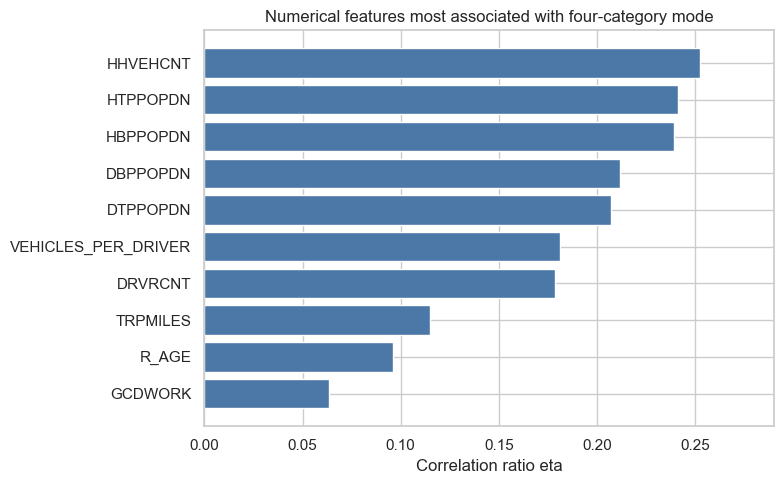

In [12]:
summary_features = [
    feature
    for feature in [
        "R_AGE", "HHVEHCNT", "DRVRCNT", "GCDWORK", "TRPMILES",
        "HBPPOPDN", "HTPPOPDN", "DBPPOPDN", "DTPPOPDN",
    ]
    if feature in clean.columns
]
mode_numeric_summary = clean.groupby("mode_4cat", observed=False)[summary_features].median().T
mode_numeric_summary.columns = [str(c) for c in mode_numeric_summary.columns]
print("Unweighted median values by four-category mode")
display(mode_numeric_summary.style.format("{:.2f}"))

plot_data = numeric_mode4.head(10).sort_values("Correlation ratio eta")
plt.figure(figsize=(8, 5))
plt.barh(plot_data["Feature"], plot_data["Correlation ratio eta"], color="#4C78A8")
plt.xlabel("Correlation ratio eta")
plt.title("Numerical features most associated with four-category mode")
plt.xlim(0, max(0.05, plot_data["Correlation ratio eta"].max() * 1.15))
plt.tight_layout()
plt.show()

## 10. Categorical-feature association with transport mode

Cramer's V measures the strength of association between each categorical feature and the mode outcome. To understand direction, inspect the weighted mode-share tables in the following section.

Four-category mode outcome


,Feature,Cramer's V,Complete records,Unadjusted p-value
8,ZERO_VEHICLE,0.546,4269,5.48e-276
3,DRIVER,0.506,4269,3.37e-237
5,RAIL,0.207,4269,3.28e-40
6,MSACAT,0.120,4269,8.21e-37
7,URBRUR,0.093,4269,1.1e-08
4,HHFAMINC,0.086,4207,2.25e-13
1,EDUC,0.080,4269,9.67e-13
2,WORKER,0.051,4269,0.00282
0,R_SEX_IMP,0.031,4269,0.0654
9,DEPARTURE_PERIOD,0.022,4266,0.09


Three-category mode outcome


,Feature,Cramer's V,Complete records,Unadjusted p-value
8,ZERO_VEHICLE,0.541,4269,1.41e-272
3,DRIVER,0.505,4269,2.69e-237
5,RAIL,0.208,4269,4.17e-41
6,MSACAT,0.146,4269,5.12e-38
7,URBRUR,0.092,4269,4.98e-09
4,HHFAMINC,0.092,4207,4.52e-11
1,EDUC,0.091,4269,3.9e-12
2,WORKER,0.053,4269,0.000936
0,R_SEX_IMP,0.034,4269,0.0297
9,DEPARTURE_PERIOD,0.024,4266,0.0858


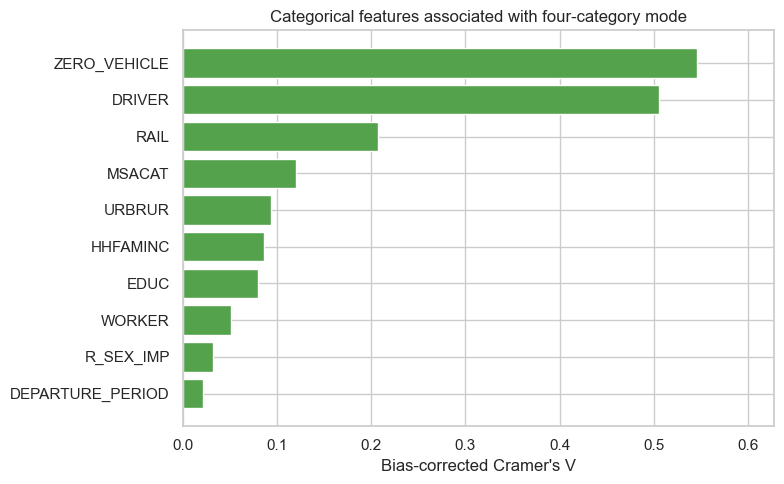

In [13]:
def categorical_mode_associations(df, mode_column):
    rows = []
    for feature in CATEGORICAL_FEATURES:
        value, p_value, n = cramers_v(df[feature], df[mode_column])
        rows.append({
            "Feature": feature,
            "Cramer's V": value,
            "Complete records": n,
            "Unadjusted p-value": p_value,
        })
    return pd.DataFrame(rows).sort_values("Cramer's V", ascending=False)


categorical_mode4 = categorical_mode_associations(clean, "mode_4cat")
categorical_mode3 = categorical_mode_associations(clean, "mode_3cat")

print("Four-category mode outcome")
display(categorical_mode4.style.format({
    "Cramer's V": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

print("Three-category mode outcome")
display(categorical_mode3.style.format({
    "Cramer's V": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

plot_data = categorical_mode4.sort_values("Cramer's V")
plt.figure(figsize=(8, 5))
plt.barh(plot_data["Feature"], plot_data["Cramer's V"], color="#54A24B")
plt.xlabel("Bias-corrected Cramer's V")
plt.title("Categorical features associated with four-category mode")
plt.xlim(0, max(0.05, plot_data["Cramer's V"].max() * 1.15))
plt.tight_layout()
plt.show()

## 11. Direction of important categorical relationships

Association strength alone does not show which mode is more common in each category. These tables calculate `WTTRDFIN5D`-weighted mode shares within selected predictor categories.

Read each row horizontally. A row adds to approximately 100% across the four modes.

In [14]:
def weighted_mode_share_by(df, predictor, mode="mode_4cat", weight="WTTRDFIN5D"):
    needed = [predictor, mode, weight]
    if not all(column in df.columns for column in needed):
        return pd.DataFrame()
    subset = df[needed].dropna()
    weighted = subset.groupby([predictor, mode], observed=False)[weight].sum().unstack(fill_value=0)
    weighted = weighted.reindex(columns=MODE4_ORDER, fill_value=0)
    return weighted.div(weighted.sum(axis=1), axis=0) * 100


direction_features = [
    feature for feature in ["DRIVER", "ZERO_VEHICLE", "RAIL", "URBRUR", "DEPARTURE_PERIOD"]
    if feature in clean.columns
]

for feature in direction_features:
    print(f"Weighted mode share within {feature} categories")
    table = weighted_mode_share_by(clean, feature)
    display(table.style.format("{:.2f}"))

Weighted mode share within DRIVER categories


mode_4cat,car,public_transport,walking,cycling
DRIVER,,,,
1,97.21,0.87,1.54,0.39
2,26.26,37.76,27.13,8.84


Weighted mode share within ZERO_VEHICLE categories


mode_4cat,car,public_transport,walking,cycling
ZERO_VEHICLE,,,,
no,97.18,0.69,1.48,0.65
yes,28.94,41.85,28.14,1.08


Weighted mode share within RAIL categories


mode_4cat,car,public_transport,walking,cycling
RAIL,,,,
1,87.60,7.98,3.10,1.32
2,96.89,0.44,2.18,0.49


Weighted mode share within URBRUR categories


mode_4cat,car,public_transport,walking,cycling
URBRUR,,,,
1,93.64,2.65,2.97,0.73
2,99.35,0.00,0.22,0.42


Weighted mode share within DEPARTURE_PERIOD categories


mode_4cat,car,public_transport,walking,cycling
DEPARTURE_PERIOD,,,,
evening_peak,95.61,1.93,1.70,0.76
midday,93.45,2.49,3.28,0.78
morning_peak,94.92,2.20,2.09,0.78
night,95.87,1.47,2.59,0.07


## 12. Automatic evidence summary

This cell collects the strongest observed relationships. “Strongest” means largest effect size within this candidate set. It does not mean causal, unbiased, or ready for policy interpretation.

In [15]:
print("Strongest numerical or ordered predictor pairs")
display(spearman_pairs.head(10)[
    ["Feature 1", "Feature 2", "Spearman rho", "Complete pairs", "Unadjusted p-value"]
].style.format({"Spearman rho": "{:.3f}", "Unadjusted p-value": "{:.3g}"}))

print("Numerical features most associated with four-category mode")
display(numeric_mode4.head(8)[
    ["Feature", "Correlation ratio eta", "Eta squared", "Complete records", "Unadjusted p-value"]
].style.format({
    "Correlation ratio eta": "{:.3f}",
    "Eta squared": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

print("Categorical features most associated with four-category mode")
display(categorical_mode4.head(8).style.format({
    "Cramer's V": "{:.3f}",
    "Unadjusted p-value": "{:.3g}",
}))

Strongest numerical or ordered predictor pairs


,Feature 1,Feature 2,Spearman rho,Complete pairs,Unadjusted p-value
50,GCDWORK,TRPMILES,0.884,3813,0
63,HBPPOPDN,HTPPOPDN,0.835,4237,0
72,DBPPOPDN,DTPPOPDN,0.817,4223,0
13,HHSIZE,DRVRCNT,0.707,4269,0
69,HTPPOPDN,DTPPOPDN,0.701,4231,0
23,HHVEHCNT,DRVRCNT,0.691,4269,0
64,HBPPOPDN,DBPPOPDN,0.660,4227,0
65,HBPPOPDN,DTPPOPDN,0.601,4222,0
33,DRVRCNT,WRKCOUNT,0.600,4269,0
68,HTPPOPDN,DBPPOPDN,0.590,4224,0


Numerical features most associated with four-category mode


,Feature,Correlation ratio eta,Eta squared,Complete records,Unadjusted p-value
2,HHVEHCNT,0.252,0.064,4269,1.99e-59
8,HTPPOPDN,0.241,0.058,4256,2.27e-47
7,HBPPOPDN,0.239,0.057,4250,1.91e-48
9,DBPPOPDN,0.212,0.045,4237,1.84e-36
10,DTPPOPDN,0.207,0.043,4240,1.1e-33
11,VEHICLES_PER_DRIVER,0.181,0.033,4233,7.78e-37
3,DRVRCNT,0.179,0.032,4269,3.08e-26
6,TRPMILES,0.115,0.013,4269,1.08e-60


Categorical features most associated with four-category mode


,Feature,Cramer's V,Complete records,Unadjusted p-value
8,ZERO_VEHICLE,0.546,4269,5.48e-276
3,DRIVER,0.506,4269,3.37e-237
5,RAIL,0.207,4269,3.28e-40
6,MSACAT,0.120,4269,8.21e-37
7,URBRUR,0.093,4269,1.1e-08
4,HHFAMINC,0.086,4207,2.25e-13
1,EDUC,0.080,4269,9.67e-13
2,WORKER,0.051,4269,0.00282


## 13. How to interpret the results

### Main patterns in the current data

- `GCDWORK` and `TRPMILES` have a Spearman correlation of approximately **0.884**. They contain strongly overlapping distance information. `GCDWORK` remains the preferred pre-choice distance measure because `TRPMILES` can partly reflect the route and mode selected.
- Home population density and home transit density have a correlation of approximately **0.835**. Destination population density and destination transit density have a correlation of approximately **0.817**. Including all density measures together may add redundant information.
- Household size and licensed-driver count have a correlation of approximately **0.707**. Household vehicle count and licensed-driver count have a correlation of approximately **0.691**.
- The strongest numerical or ordered association with four-category mode is household vehicle count, with eta approximately **0.252**. Home and destination density measures follow with eta values around **0.21 to 0.24**.
- The strongest categorical mode associations are zero-vehicle household status with Cramer's V approximately **0.546**, driver status with approximately **0.506**, and the `RAIL` field with approximately **0.207**.
- In weighted descriptive results, households with vehicles have approximately **97.18%** car trips, while zero-vehicle households have approximately **28.94%** car, **41.85%** public transport, and **28.14%** walking. Zero-vehicle households are rare in this study sample, so these estimates need uncertainty checks.
- `RAIL` and `MSACAT` have Cramer's V approximately **0.979**, indicating that they carry almost the same categorical information in this sample. Their official definitions and skip patterns must be reviewed before deciding which one to retain.

These are exploratory associations. They do not show that changing vehicle ownership, density, rail access, or any other feature would cause a change in mode.

Use the results to refine the feature list, not to make causal conclusions.

1. **Check redundant predictors.** A large absolute Spearman correlation or Cramer's V suggests that two predictors contain overlapping information. Examples may include vehicle count with driver count, or urban classification with density.
2. **Inspect outcome associations.** Eta and Cramer's V identify features whose distributions differ most across modes.
3. **Read direction from group summaries.** Eta and Cramer's V have no direction. The medians and weighted mode-share tables show which categories or values are connected to each mode.
4. **Prioritize pre-choice features.** Keep variables that were known before mode choice and have a clear planning interpretation.
5. **Keep the future model small.** There are only 77 public-transport trips, 99 walking trips, and 31 cycling trips in the four-category sample.
6. **Use three categories as a sensitivity option.** Combining walking and cycling creates 130 active-travel trips, but the public-transport class remains small.

## Important limitations

- Correlation and association do not establish causation.
- These exploratory p-values do not account for repeated trips, household clustering, survey strata, or multiple comparisons.
- The effect-size calculations are unweighted. Weighted mode shares are reported separately.
- Negative NHTS codes were excluded from calculations, but the official codebook must determine their final treatment variable by variable.
- `TRPMILES` may partly depend on the chosen route and mode. `GCDWORK` is the preferred pre-choice commute-distance approximation when available.
- Residential density, rail access, and vehicle ownership can reflect residential or lifestyle self-selection.

## Recommended next step

Review the strongest relationships against the official codebook. Then select a small, conceptually justified feature set. A staged future model could begin with age, driver status, household vehicle availability, household income, commute distance, and one or two accessibility measures. Modelling should account for survey design and the clustering of trips within people and households.